Q15. Model Explainability using Permutation Importance

Using the Breast Cancer Wisconsin dataset, train a Random Forest classifier and
calculate permutation feature importance on the test set. Display the top five features
according to their importance. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

In [2]:


# Step 2: Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [5]:
result = permutation_importance(
    model, X_test, y_test, n_repeats=5, random_state=42
)


Top 5 Important Features:
['mean texture', 'mean area', 'worst texture', 'worst radius', 'worst concave points']


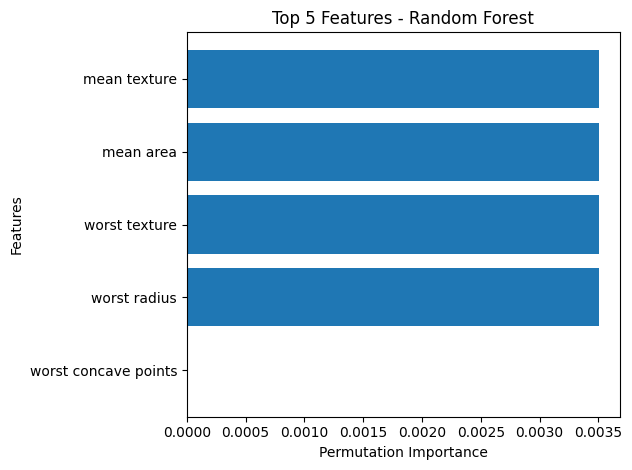

In [ ]:
import numpy as np 
importance = result.importances_mean
top5 = np.argsort(importance)[-5:]

# Step 7: Display bar graph
plt.barh(X.columns[top5], importance[top5])
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Top 5 Features - Random Forest")
plt.tight_layout()
plt.show()
